# EDA do DermaMNIST — Projeto CIN0040 (ViT / SL-ViT / CL-ViT com dados reduzidos)

**Objetivo do notebook.** Entender o DermaMNIST *antes* de treinar e transformar cada achado em uma decisão de projeto (normalização, interpolação, patch, balanceamento, cuidados na avaliação).

**Como usar.** Rode de cima para baixo. Todas as figuras vão para `reports/figures/` (300 dpi) e os números-chave são acumulados em `SUMMARY` e salvos em `reports/eda_summary.json` e `reports/normalization.json` (para o script de treino ler, em vez de copiar à mão).

**Estrutura de cada etapa:** *Objetivo → O que procurar → Impacto na decisão → Código.*

### Princípios do protocolo (valem para o notebook inteiro)
1. **Nenhuma decisão olha o teste.** Tudo que entra no treino (média/desvio, pesos de classe, priors, margens, sampler) sai **só de `y['train']`**. Limiares e offsets pós-hoc saem **só da validação**.
2. O teste aparece aqui apenas em **auditorias descritivas** (distribuição de classes, checagem de vazamento). Nunca para mudar split, receita ou hiperparâmetro. Documente isso no relatório.
3. Os splits oficiais do MedMNIST **não são alterados**.
4. Números citados nas explicações (≈10.015 imagens, 7.007/1.003/2.005, nevo ≈67%, IR ≈58) são **valores esperados**. O notebook os **verifica** com `assert`/impressão; não os assuma.

### Mapa das etapas
| # | Etapa | Prioridade |
|---|---|---|
| 1 | Carga, shapes, dtypes, ranges, mapeamento de classes | Indispensável |
| 2 | Distribuição de classes por split | Indispensável |
| 3 | Exemplos por classe, 28 vs 32, interpolação | Indispensável |
| 4 | Estatísticas de pixel (normalização, brilho, contraste, cor) | Indispensável |
| 5 | Qualidade: atípicas, duplicatas, vazamento | Indispensável |
| 6 | Separabilidade (PCA / t-SNE / UMAP) | Recomendada |
| 7 | Impacto da resolução (28/32 vs 64) | Opcional |
| 8 | Implicações para os ViTs (patch, tokens, SPT, CutMix, params/amostra) | Indispensável |
| 9 | Ponte para o balanceamento e para as extensões (10/25/50% e 5-fold) | Indispensável |
| 10 | Resumo e checklist para o relatório IEEE | Indispensável |

## 0. Setup
Instale as dependências (necessário no Colab; descomente a linha). `umap-learn` só é usado na Etapa 6 e o notebook funciona sem ele.

In [ ]:
%pip install -q medmnist umap-learn scikit-learn seaborn

In [1]:
import os, json, hashlib, warnings
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from IPython.display import display
import medmnist
from medmnist import INFO, DermaMNIST

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# Pastas (ajuste se necessário; no Colab "./data" e "./reports" ficam na sessão)
DATA_DIR = os.path.abspath("./data")
OUT_DIR  = os.path.abspath("./reports")
FIG_DIR  = os.path.join(OUT_DIR, "figures")
for d in (DATA_DIR, FIG_DIR): os.makedirs(d, exist_ok=True)

# Estilo: dpi baixo na tela (notebook leve) e 300 dpi apenas ao salvar
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.dpi': 100, 'savefig.dpi': 300})

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), bbox_inches='tight')

SUMMARY = {}   # acumula os números que irão para o relatório

print(f"medmnist {medmnist.__version__} | torch {torch.__version__} | numpy {np.__version__} | device {DEVICE} | seed {SEED}")
SUMMARY['versoes'] = dict(medmnist=medmnist.__version__, torch=torch.__version__, numpy=np.__version__, seed=SEED)

medmnist 3.0.2 | torch 2.14.1+cu130 | numpy 2.2.6 | device cpu | seed 42


## Etapa 1 — Carregamento, shapes, dtypes, ranges e mapeamento de classes

**Objetivo.** Garantir que você usa os splits oficiais, que os dados são o que se espera e que o **mapeamento índice → classe vem do `INFO`**, não de um dicionário digitado à mão.

**Por que isso importa.** O DermaMNIST segue a ordem alfabética dos códigos do HAM10000 (akiec, bcc, bkl, df, **mel**, **nv**, vasc), então **melanoma = 4 e nevo = 5**. Digitar o dicionário errado (por exemplo, trocando 4 e 5) faz o "recall do melanoma" ser calculado sobre os nevos e invalida todo o resultado. Por isso o código acha as classes-chave **pelo nome** e confere por contagem (o nevo deve ser a classe majoritária e o melanoma bem menor).

**O que procurar.**
- `imgs`: shape `(N, 28, 28, 3)`, dtype `uint8`, range [0, 255].
- `labels`: shape `(N, 1)` (dimensão extra, é preciso `.ravel()`), valores em `{0..6}`.
- Soma e tamanho de cada split iguais ao `INFO['dermamnist']['n_samples']`.

**Impacto.** Erro de dtype/range (esquecer o `/255`) quebra a normalização em silêncio; rótulo `(N,1)` dá erro na `CrossEntropyLoss`.

In [26]:
info = INFO['dermamnist']
names = {int(k): v for k, v in info['label'].items()}
K = len(names)

def short_code(label):
    """Nome longo do INFO -> código curto do HAM10000 (decidido pelo NOME, não pelo índice)."""
    l = label.strip().lower()
    if l == 'melanoma': return 'mel'
    for key, c in [('actinic', 'akiec'), ('basal', 'bcc'), ('benign keratosis', 'bkl'),
                   ('dermatofibroma', 'df'), ('nevi', 'nv'), ('vascular', 'vasc')]:
        if key in l: return c
    return l[:6]

CODES = {k: short_code(v) for k, v in names.items()}
assert len(set(CODES.values())) == K, f"Mapeamento de códigos ambíguo: {CODES}"
MEL = next(k for k, c in CODES.items() if c == 'mel')
NEV = next(k for k, c in CODES.items() if c == 'nv')
print("Mapeamento (do INFO):"); [print(f"  {k}: {names[k]}  ->  {CODES[k]}") for k in range(K)]

SPLITS = ['train', 'val', 'test']
try:
    ds = {s: DermaMNIST(split=s, download=True, root=DATA_DIR, size=28) for s in SPLITS}   # medmnist >= 3.0
except TypeError:
    ds = {s: DermaMNIST(split=s, download=True, root=DATA_DIR) for s in SPLITS}            # versões antigas (já 28x28)

X = {s: np.asarray(ds[s].imgs) for s in SPLITS}                           # (N,28,28,3) uint8
y = {s: np.asarray(ds[s].labels).ravel().astype(int) for s in SPLITS}     # (N,)

rows = [dict(split=s, n=len(X[s]), shape=X[s].shape[1:], dtype=str(X[s].dtype),
             min=int(X[s].min()), max=int(X[s].max()),
             labels_shape_original=np.asarray(ds[s].labels).shape,
             classes=sorted(np.unique(y[s]).tolist())) for s in SPLITS]
display(pd.DataFrame(rows))

# --- Verificações (falham alto se algo estiver diferente do esperado)
assert all(X[s].dtype == np.uint8 and X[s].ndim == 4 and X[s].shape[-1] == 3 for s in SPLITS)
assert all(set(np.unique(y[s])) <= set(range(K)) for s in SPLITS)
for s in SPLITS:
    assert len(X[s]) == info['n_samples'][s], f"{s}: {len(X[s])} != INFO {info['n_samples'][s]}"
n_total = sum(len(X[s]) for s in SPLITS)
print(f"\nTotal = {n_total} imagens | splits (treino/val/teste) = {[len(X[s]) for s in SPLITS]}")

# Sanidade do mapeamento: nevo deve ser a classe majoritária e o melanoma muito menor
cnt_tr = np.bincount(y['train'], minlength=K)
assert cnt_tr.argmax() == NEV, "A classe majoritária deveria ser o nevo: confira o mapeamento!"
assert cnt_tr[MEL] < cnt_tr[NEV]
SUMMARY['mapeamento'] = {int(k): dict(nome=names[k], codigo=CODES[k]) for k in range(K)}
SUMMARY['indice_melanoma'], SUMMARY['indice_nevo'] = int(MEL), int(NEV)
SUMMARY['n_total'] = int(n_total)

Mapeamento (do INFO):
  0: actinic keratoses and intraepithelial carcinoma  ->  akiec
  1: basal cell carcinoma  ->  bcc
  2: benign keratosis-like lesions  ->  bkl
  3: dermatofibroma  ->  df
  4: melanoma  ->  mel
  5: melanocytic nevi  ->  nv
  6: vascular lesions  ->  vasc


,split,n,shape,dtype,min,max,labels_shape_original,classes
0,train,7007,"(28, 28, 3)",uint8,0,255,"(7007, 1)","[0, 1, 2, 3, 4, 5, 6]"
1,val,1003,"(28, 28, 3)",uint8,0,255,"(1003, 1)","[0, 1, 2, 3, 4, 5, 6]"
2,test,2005,"(28, 28, 3)",uint8,0,255,"(2005, 1)","[0, 1, 2, 3, 4, 5, 6]"



Total = 10015 imagens | splits (treino/val/teste) = [7007, 1003, 2005]


In [3]:
# Redimensionamento 28 -> 32 (a interpolação definitiva é decidida na Etapa 3).
INTERP = 'bilinear'   # DECISÃO: precisa ser IDÊNTICA à usada no pipeline de treino (confira o transform do repositório)

def resize_np(x_uint8, size=32, mode=None, antialias=False):
    """uint8 NHWC -> float32 NCHW em [0,1], redimensionado e com clamp (bicúbica pode extrapolar)."""
    mode = mode or INTERP
    t = torch.from_numpy(np.ascontiguousarray(x_uint8)).permute(0, 3, 1, 2).float() / 255.
    if size != t.shape[-1]:
        kw = {} if mode in ('nearest', 'area') else dict(align_corners=False, antialias=antialias)
        t = F.interpolate(t, size=(size, size), mode=mode, **kw)
    return t.clamp(0, 1)

def to_uint8_img(t):   # (1,3,H,W) float -> (H,W,3) uint8, para mostrar
    return (t[0].permute(1, 2, 0).numpy() * 255).round().astype('uint8')

def jsonable(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, torch.Tensor): return o.tolist()
    return str(o)

## Etapa 2 — Distribuição de classes por split

**Objetivo.** Quantificar o desbalanceamento e verificar se treino/val/teste preservam as proporções.

**O que procurar.**
- **Razão de desbalanceamento** `IR = n_max / n_min` (esperado: ordem de 50:1, com nevo ≈ 2/3 e df/vasc ≈ 1% cada).
- **Acurácia do classificador trivial** (sempre prever a classe majoritária). Se for ≈ 67%, uma acurácia de 70% é praticamente inútil, e isso justifica AUC-ROC, F1 macro e recall por classe como métricas principais.
- **Teste qui-quadrado entre splits**: p alto = proporções compatíveis (split provavelmente estratificado ou aleatório bem-comportado).
- **Contagens absolutas das classes raras em val e teste.** Com poucas dezenas de amostras, o recall dessas classes terá **intervalos de confiança largos** (calculados abaixo): você não poderá afirmar diferenças pequenas entre modelos nessas classes.

**Impacto.** Define a intensidade do balanceamento (Etapa 9) e quanto confiar nas métricas por classe.

,train,val,test,total
akiec,228,33,66,327
bcc,359,52,103,514
bkl,769,110,220,1099
df,80,12,23,115
mel,779,111,223,1113
nv,4693,671,1341,6705
vasc,99,14,29,142


,train (%),val (%),test (%)
akiec,3.25,3.29,3.29
bcc,5.12,5.18,5.14
bkl,10.97,10.97,10.97
df,1.14,1.20,1.15
mel,11.12,11.07,11.12
nv,66.98,66.90,66.88
vasc,1.41,1.40,1.45


IR (treino) = 58.7:1  [nv = 4693  vs  df = 80]
Acurácia do classificador trivial: {'train': 0.67, 'val': 0.669, 'test': 0.669}
Qui-quadrado (proporções iguais entre splits): p = 1.000  (p alto => compatíveis)
Menor contagem esperada na tabela (regra prática: >= 5): 11.5


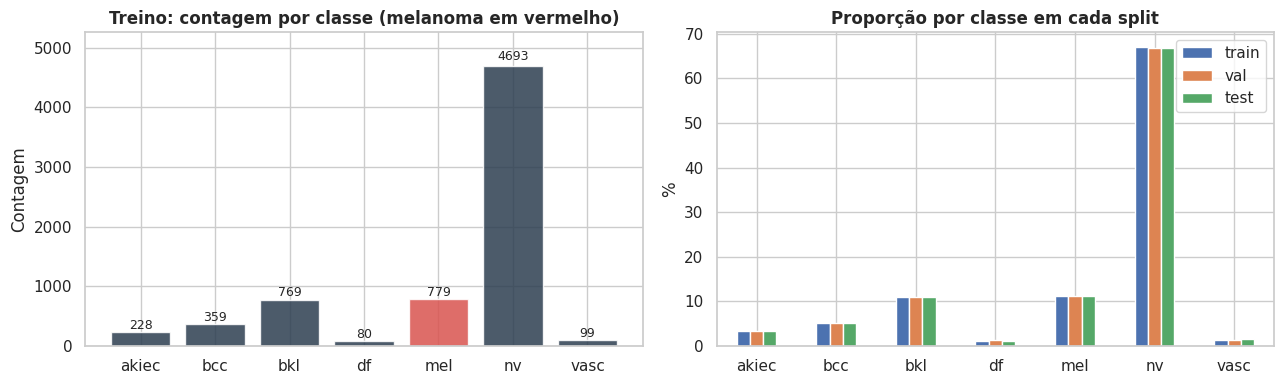


Precisão possível do recall por classe (IC de Wilson, pior caso):


,n_val,±IC95_val,n_teste,±IC95_teste
akiec,33,0.161,66,0.117
bcc,52,0.131,103,0.095
bkl,110,0.092,220,0.066
df,12,0.246,23,0.189
mel,111,0.091,223,0.065
nv,671,0.038,1341,0.027
vasc,14,0.232,29,0.171


In [4]:
from scipy.stats import chi2_contingency

cnt = pd.DataFrame({s: np.bincount(y[s], minlength=K) for s in SPLITS}, index=[CODES[i] for i in range(K)])
prop = cnt / cnt.sum()
display(cnt.assign(total=cnt.sum(1)))
display((prop * 100).round(2).rename(columns=lambda c: c + ' (%)'))

n_tr = cnt['train'].values
IR = n_tr.max() / n_tr.min()
trivial = {s: float(prop[s].max()) for s in SPLITS}
chi2, p_chi, _, _ = chi2_contingency(cnt[SPLITS].values)
print(f"IR (treino) = {IR:.1f}:1  [{CODES[int(n_tr.argmax())]} = {n_tr.max()}  vs  {CODES[int(n_tr.argmin())]} = {n_tr.min()}]")
print("Acurácia do classificador trivial:", {k: round(v, 3) for k, v in trivial.items()})
print(f"Qui-quadrado (proporções iguais entre splits): p = {p_chi:.3f}  (p alto => compatíveis)")
print("Menor contagem esperada na tabela (regra prática: >= 5):", round(chi2_contingency(cnt[SPLITS].values)[3].min(), 1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
colors = ['#d9534f' if i == MEL else '#2c3e50' for i in range(K)]   # melanoma em vermelho (pelo NOME)
bars = ax[0].bar([CODES[i] for i in range(K)], n_tr, color=colors, alpha=.85)
for b in bars:
    ax[0].text(b.get_x() + b.get_width() / 2, b.get_height() * 1.01, f'{int(b.get_height())}', ha='center', va='bottom', fontsize=9)
ax[0].set_ylim(0, n_tr.max() * 1.12); ax[0].set_ylabel("Contagem"); ax[0].set_title("Treino: contagem por classe (melanoma em vermelho)", fontweight='bold')
(prop * 100).plot.bar(ax=ax[1], rot=0); ax[1].set_ylabel("%"); ax[1].set_title("Proporção por classe em cada split", fontweight='bold')
plt.tight_layout(); savefig("eda_dermamnist_imbalance.png"); plt.show()

# Quão ruidoso será o recall por classe? Meia-largura do IC de Wilson (95%) no pior caso p=0,5
def wilson_halfwidth(n, p=0.5, z=1.96):
    return z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
ci = pd.DataFrame({'n_val': cnt['val'], '±IC95_val': [wilson_halfwidth(n) for n in cnt['val']],
                   'n_teste': cnt['test'], '±IC95_teste': [wilson_halfwidth(n) for n in cnt['test']]}).round(3)
print("\nPrecisão possível do recall por classe (IC de Wilson, pior caso):"); display(ci)

SUMMARY['distribuicao'] = dict(contagens={s: cnt[s].to_dict() for s in SPLITS}, IR_treino=float(IR),
                               acuracia_trivial=trivial, qui2_p=float(p_chi))

## Etapa 3 — Exemplos por classe, 28×28 vs 32×32 e escolha da interpolação

**Objetivo.** Ver o que o modelo vê, medir variabilidade intra-classe/semelhança inter-classe e escolher o redimensionamento.

**O que procurar.**
- Variabilidade dentro da classe (cor, tamanho, posição da lesão) e semelhança entre classes (melanoma × nevo × ceratose benigna).
- A lesão está sempre **centralizada**? Isso afeta o CutMix (Etapa 8).
- Artefatos do redimensionamento.

**Sobre interpolação (28→32, fator ≈1,14, ampliação).** `nearest` duplica alguns pixels e outros não (padrão irregular): evite. `bilinear` e `bicubic` são adequados; a bicúbica pode extrapolar, por isso o `clamp`. O `antialias` só faz diferença na *redução*. **Ampliar não cria informação.** A comparação por *round-trip* abaixo mede fidelidade (quanto o redimensionamento distorce), não "qualidade clínica".

**Decisão.** A escolha importa menos que **usar exatamente a mesma interpolação em todos os modelos** e a mesma do repositório de treino. Registre-a no relatório.

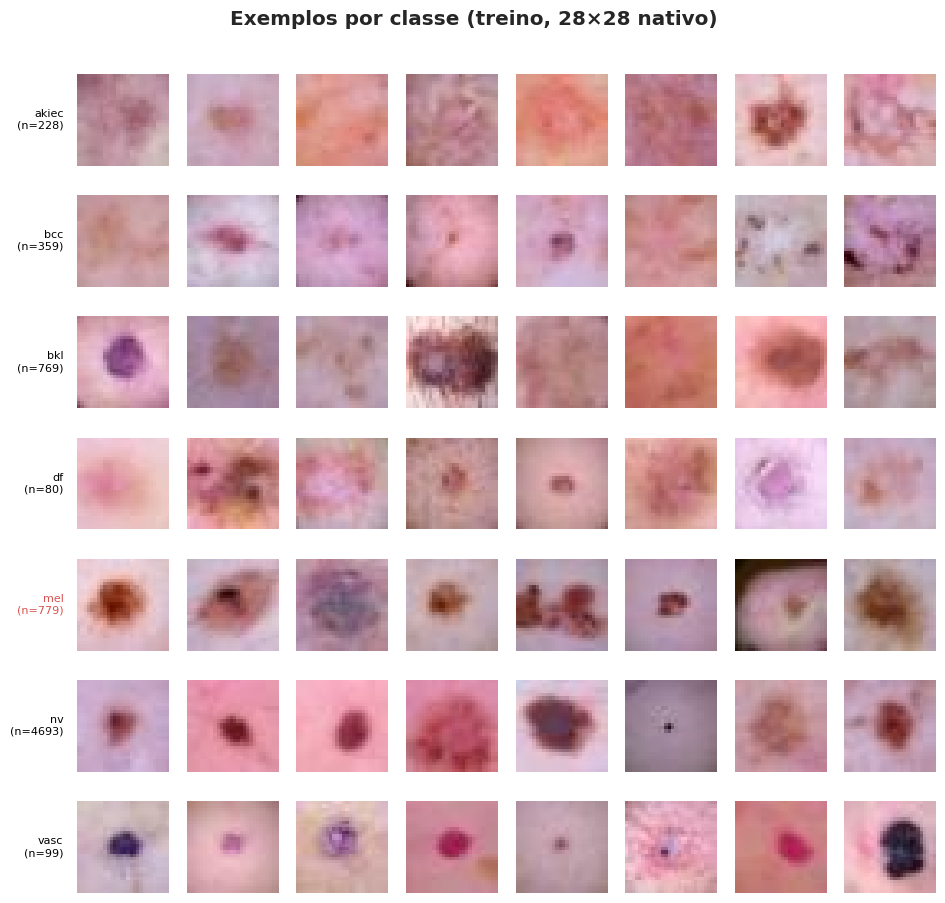

In [5]:
def class_grid(Xs, ys, n=8, seed=SEED, fname=None):
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(K, n, figsize=(n * 1.2, K * 1.3))
    for c in range(K):
        pool = np.where(ys == c)[0]
        idx = rng.choice(pool, min(n, len(pool)), replace=False)
        for j in range(n):
            axes[c, j].axis('off')
            if j < len(idx): axes[c, j].imshow(Xs[idx[j]], interpolation='nearest')
        axes[c, 0].text(-0.15, .5, f"{CODES[c]}\n(n={len(pool)})", transform=axes[c, 0].transAxes, ha='right', va='center',
                        fontsize=8, color='#d9534f' if c == MEL else 'black')
    fig.suptitle("Exemplos por classe (treino, 28×28 nativo)", fontweight='bold', y=1.0)
    plt.tight_layout()
    if fname: savefig(fname)
    plt.show()
class_grid(X['train'], y['train'], fname="eda_dermamnist_samples_grid.png")

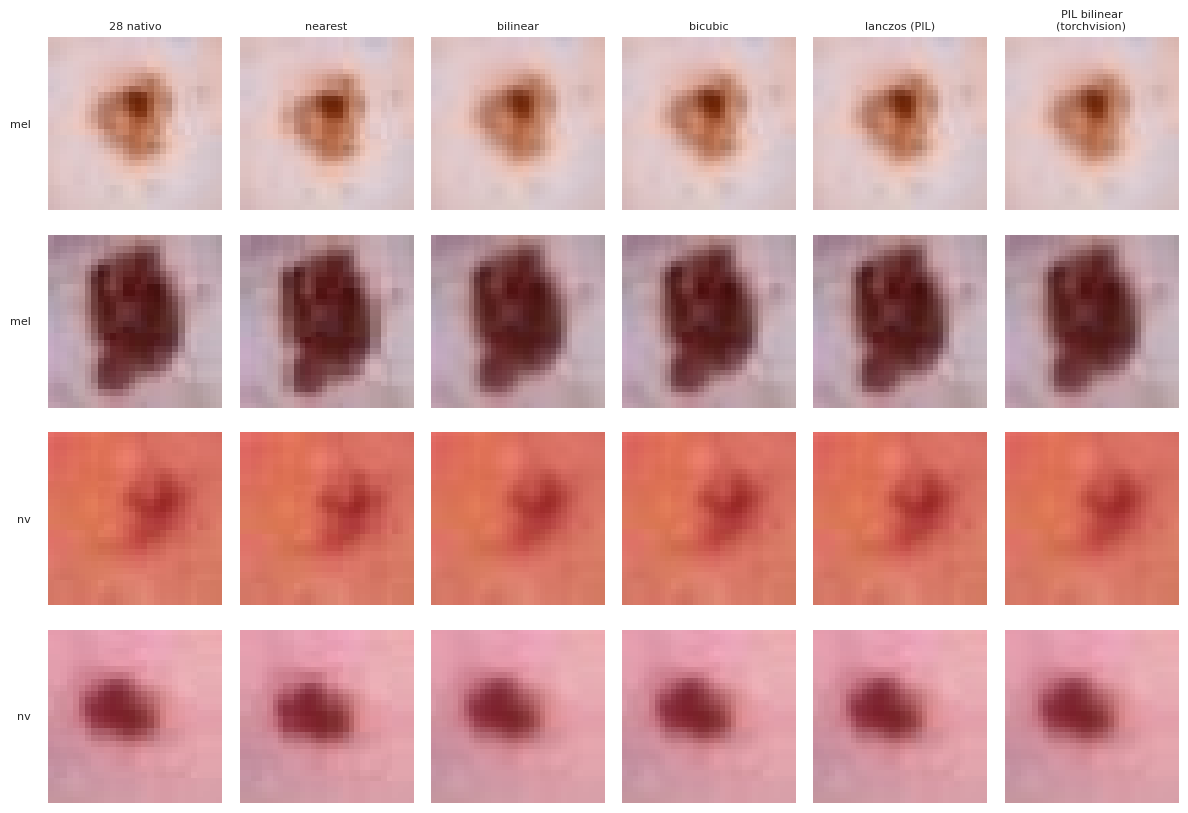

MAE bilinear(torch) vs bicubic      : 0.00301
MAE bilinear(torch) vs PIL bilinear : 0.00113   (confirma se torch ~ torchvision.Resize)
MAE nearest vs bilinear             : 0.01343
Round-trip MAE (28->32->28): {'nearest': 0.01302, 'bilinear': 0.0052, 'bicubic': 0.00312}


In [6]:
# --- Comparação visual de interpolações (2 melanomas e 2 nevos); imshow 'nearest' para ver os pixels reais
idxs = list(np.where(y['train'] == MEL)[0][:2]) + list(np.where(y['train'] == NEV)[0][:2])
def pil_resize(img, resample): return np.array(Image.fromarray(img).resize((32, 32), resample))

cols = ['28 nativo', 'nearest', 'bilinear', 'bicubic', 'lanczos (PIL)', 'PIL bilinear\n(torchvision)']
fig, axes = plt.subplots(len(idxs), len(cols), figsize=(2 * len(cols), 2.1 * len(idxs)))
for r, i in enumerate(idxs):
    img = X['train'][i]
    ims = [img] + [to_uint8_img(resize_np(img[None], 32, m)) for m in ('nearest', 'bilinear', 'bicubic')] \
        + [pil_resize(img, Image.LANCZOS), pil_resize(img, Image.BILINEAR)]
    for c, im in enumerate(ims):
        axes[r, c].imshow(im, interpolation='nearest'); axes[r, c].axis('off')
        if r == 0: axes[r, c].set_title(cols[c], fontsize=8)
    axes[r, 0].text(-0.1, .5, CODES[y['train'][i]], transform=axes[r, 0].transAxes, ha='right', va='center', fontsize=8)
plt.tight_layout(); savefig("eda_interpolacao.png"); plt.show()

# --- Quantificação 1: diferença entre métodos (se ~0, a escolha é irrelevante na prática)
smp = X['train'][:1000]
up = {m: resize_np(smp, 32, m) for m in ('nearest', 'bilinear', 'bicubic')}
tv = torch.from_numpy(np.stack([pil_resize(a, Image.BILINEAR) for a in smp])).permute(0, 3, 1, 2).float() / 255.
mae = lambda a, b: (a - b).abs().mean().item()
print(f"MAE bilinear(torch) vs bicubic      : {mae(up['bilinear'], up['bicubic']):.5f}")
print(f"MAE bilinear(torch) vs PIL bilinear : {mae(up['bilinear'], tv):.5f}   (confirma se torch ~ torchvision.Resize)")
print(f"MAE nearest vs bilinear             : {mae(up['nearest'], up['bilinear']):.5f}")

# --- Quantificação 2: fidelidade por round-trip 28 -> 32 -> 28 (menor = distorce menos)
base = resize_np(smp, 28)
rt = {m: mae(F.interpolate(up[m], size=(28, 28), mode='bilinear', align_corners=False, antialias=True), base) for m in up}
print("Round-trip MAE (28->32->28):", {k: round(v, 5) for k, v in rt.items()})
SUMMARY['interpolacao'] = dict(escolhida=INTERP, round_trip_mae=rt)

## Etapa 4 — Estatísticas de pixel: normalização, brilho, contraste e cor

**Objetivo.** Obter média/desvio por canal para a normalização e entender como cor, brilho e contraste variam por classe.

**O que procurar.**
- Média/desvio **do treino, após o redimensionamento 32×32** (não use os do ImageNet nem os do CIFAR).
- **Cuidado com o desvio-padrão:** o correto é o desvio **global** (sobre todos os pixels do treino), `sqrt(E[x²] − E[x]²)`. A *média dos desvios por imagem* mede só a variação **dentro** de cada imagem e **subestima** o desvio global, deixando a normalização com escala inflada. O código mostra os dois valores para evidenciar a diferença.
- Diferenças sistemáticas de brilho/contraste/cor entre classes: se uma classe se distingue por brilho ou cor global, o modelo pode usar isso como **atalho**.
- **Imagem média e mapa de desvio por classe:** mostram onde a lesão costuma estar (centro?) e quanto varia.

**Impacto.** Normalização correta (esta é a única estatística calculada aqui que entra direto no treino). Em dermatoscopia a **cor é informação diagnóstica**, então operações de cor do AutoAugment (`Invert`, `Solarize`, `Posterize`, `Equalize`, `Color`) merecem desconfiança; confira a política usada no repositório.

In [7]:
T32 = {s: resize_np(X[s], 32) for s in SPLITS}          # float32 (N,3,32,32) em [0,1]; usa INTERP

# --- Média/desvio GLOBAIS do treino (float64)
x = T32['train'].double()
mean = x.mean((0, 2, 3))
std = ((x ** 2).mean((0, 2, 3)) - mean ** 2).sqrt()                 # desvio global (correto)
std_wrong = x.std((2, 3)).mean(0)                                   # média dos desvios por imagem (ERRADO p/ normalizar)
print("mean            =", mean.numpy().round(4))
print("std  (global)   =", std.numpy().round(4), "  <-- usar no Normalize")
print("std  (por img)  =", std_wrong.numpy().round(4), "  <-- NÃO usar (subestima)")
del x

NORM = dict(mean=[round(float(v), 6) for v in mean], std=[round(float(v), 6) for v in std],
            resolucao=32, interpolacao=INTERP, calculado_em='treino')
with open(os.path.join(OUT_DIR, "normalization.json"), "w") as f: json.dump(NORM, f, indent=2)
SUMMARY['normalizacao'] = NORM
print("Salvo em reports/normalization.json")

mean            = [0.7631 0.5381 0.5614]
std  (global)   = [0.1354 0.153  0.1679]   <-- usar no Normalize
std  (por img)  = [0.0863 0.1127 0.124 ]   <-- NÃO usar (subestima)
Salvo em reports/normalization.json


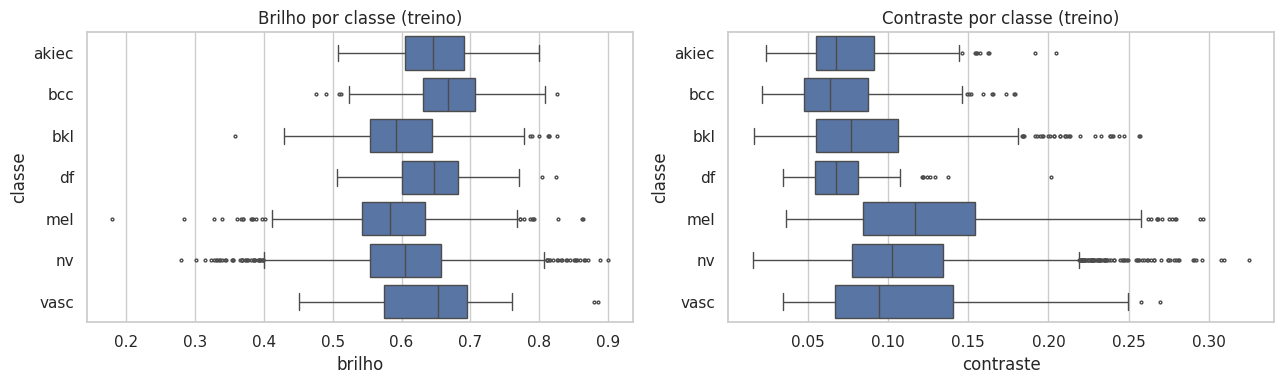

,brilho,contraste,R,G,B
classe,,,,,
akiec,0.649,0.076,0.785,0.587,0.611
bcc,0.666,0.070,0.777,0.614,0.642
bkl,0.600,0.088,0.707,0.549,0.577
df,0.647,0.073,0.782,0.583,0.618
mel,0.587,0.125,0.699,0.535,0.560
nv,0.605,0.109,0.780,0.527,0.548
vasc,0.641,0.110,0.776,0.573,0.634


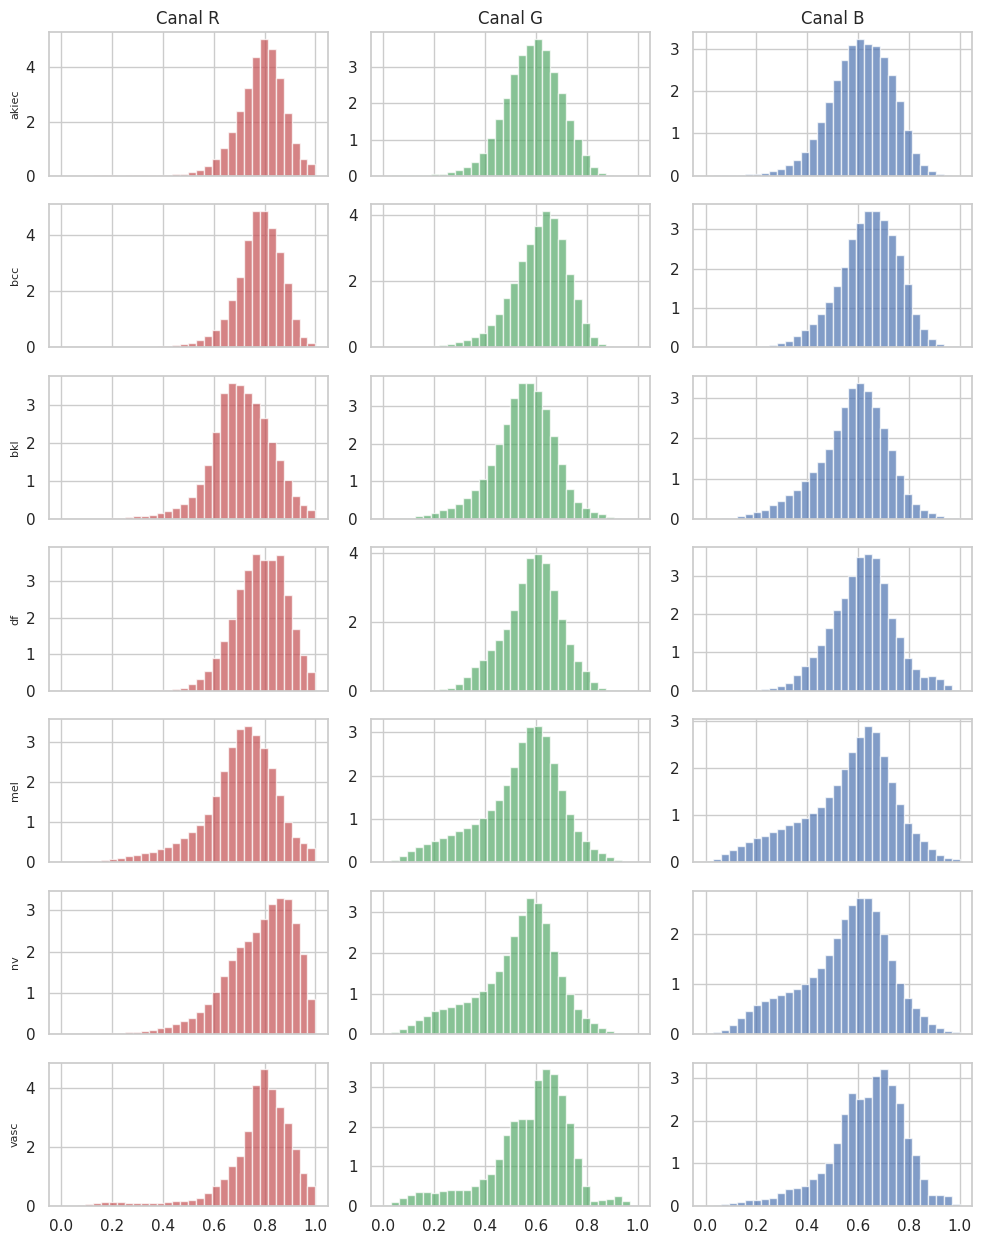

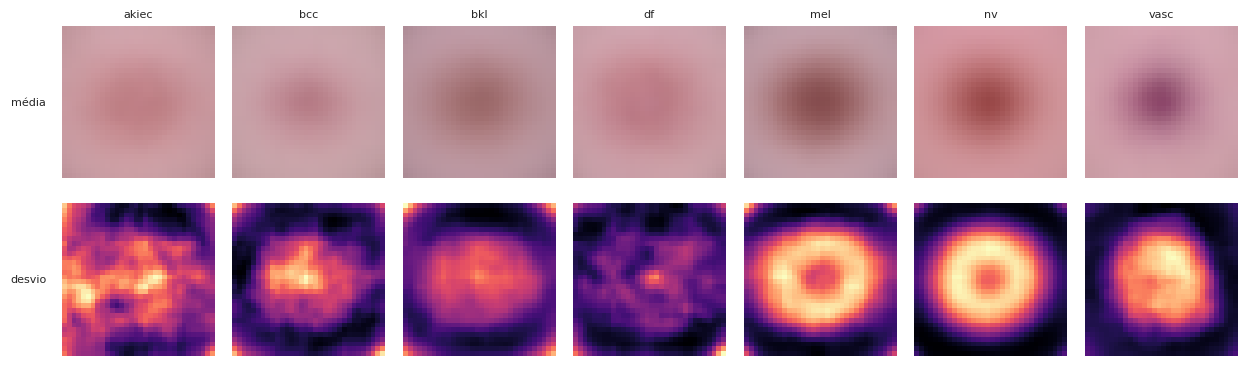

In [8]:
def img_stats(t):
    """Brilho = média da luminância; contraste = desvio da luminância; R,G,B = média por canal (por imagem)."""
    gray = 0.299 * t[:, 0] + 0.587 * t[:, 1] + 0.114 * t[:, 2]
    return pd.DataFrame({'brilho': gray.mean((1, 2)).numpy(), 'contraste': gray.std((1, 2)).numpy(),
                         'R': t[:, 0].mean((1, 2)).numpy(), 'G': t[:, 1].mean((1, 2)).numpy(), 'B': t[:, 2].mean((1, 2)).numpy()})
S = {s: img_stats(T32[s]) for s in SPLITS}
dfc = S['train'].assign(classe=[CODES[c] for c in y['train']])
order = [CODES[i] for i in range(K)]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=dfc, y='classe', x='brilho', order=order, ax=ax[0], fliersize=2)
sns.boxplot(data=dfc, y='classe', x='contraste', order=order, ax=ax[1], fliersize=2)
ax[0].set_title("Brilho por classe (treino)"); ax[1].set_title("Contraste por classe (treino)")
plt.tight_layout(); savefig("eda_brilho_contraste.png"); plt.show()
display(dfc.groupby('classe')[['brilho', 'contraste', 'R', 'G', 'B']].mean().loc[order].round(3))

# Histogramas de intensidade por classe e canal
fig, axes = plt.subplots(K, 3, figsize=(10, 1.8 * K), sharex=True)
for c in range(K):
    sel = T32['train'][torch.from_numpy(y['train'] == c)]
    for ch, col in enumerate(['r', 'g', 'b']):
        axes[c, ch].hist(sel[:, ch].flatten().numpy(), bins=32, range=(0, 1), color=col, density=True, alpha=.7)
    axes[c, 0].set_ylabel(CODES[c], fontsize=8)
for ch, t in enumerate(['Canal R', 'Canal G', 'Canal B']): axes[0, ch].set_title(t)
plt.tight_layout(); savefig("eda_histogramas_canais.png"); plt.show()

# Imagem média e mapa de desvio por classe (onde está a lesão? o que varia?)
fig, axes = plt.subplots(2, K, figsize=(K * 1.8, 4))
for c in range(K):
    sel = T32['train'][torch.from_numpy(y['train'] == c)]
    axes[0, c].imshow(sel.mean(0).permute(1, 2, 0).numpy()); axes[0, c].set_title(CODES[c], fontsize=8)
    axes[1, c].imshow(sel.std(0).mean(0).numpy(), cmap='magma')
    axes[0, c].axis('off'); axes[1, c].axis('off')
axes[0, 0].text(-0.1, .5, "média", transform=axes[0, 0].transAxes, ha='right', va='center', fontsize=8)
axes[1, 0].text(-0.1, .5, "desvio", transform=axes[1, 0].transAxes, ha='right', va='center', fontsize=8)
plt.tight_layout(); savefig("eda_imagem_media_desvio.png"); plt.show()

In [9]:
# --- Teste de atalho: o quanto [brilho, contraste, R, G, B] (5 números por imagem) já separa as classes?
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score, confusion_matrix

fc = ['brilho', 'contraste', 'R', 'G', 'B']
sc = StandardScaler().fit(S['train'][fc])
lr = LogisticRegression(max_iter=2000, class_weight='balanced').fit(sc.transform(S['train'][fc]), y['train'])
pv = lr.predict_proba(sc.transform(S['val'][fc]))
shortcut = dict(auc_macro_val=float(roc_auc_score(y['val'], pv, multi_class='ovr', average='macro')),
                bal_acc_val=float(balanced_accuracy_score(y['val'], pv.argmax(1))),
                f1_macro_val=float(f1_score(y['val'], pv.argmax(1), average='macro')))
print(shortcut, "| referência de acaso: AUC=0.5, bal_acc≈", round(1 / K, 3))
print("Interpretação: valores bem acima do acaso indicam que cor/brilho global carregam sinal (esperado, não é bug);")
print("o modelo pode aprender esse atalho, então cuide das augmentations de cor e olhe a análise de erros por classe.")
SUMMARY['atalho_cor_brilho'] = shortcut

{'auc_macro_val': 0.7710602695814781, 'bal_acc_val': 0.33152072203594457, 'f1_macro_val': 0.26493143595852947} | referência de acaso: AUC=0.5, bal_acc≈ 0.143
Interpretação: valores bem acima do acaso indicam que cor/brilho global carregam sinal (esperado, não é bug);
o modelo pode aprender esse atalho, então cuide das augmentations de cor e olhe a análise de erros por classe.


## Etapa 5 — Qualidade: atípicas, duplicatas e possível vazamento treino/val/teste

**Contexto (a análise mais importante para a validade das conclusões).** O HAM10000 tem **várias imagens da mesma lesão** (no metadado original há um `lesion_id`). O MedMNIST não preserva o `lesion_id`, e o split é descrito como um split da base em 7:1:2. **Verifique na documentação/paper do MedMNIST se o split foi feito por lesão.** Se não foi, imagens da mesma lesão podem cair em treino e teste e **inflar as métricas**, favorecendo modelos que memorizam bem.

**5a. Imagens atípicas:** imagens constantes (desvio ≈ 0) ou com brilho/contraste extremo (|z| > 4) podem ser corrompidas ou artefatos.

**5b. Duplicatas exatas (hash MD5 dos bytes):** dentro de cada split, entre splits, e se há **conflito de rótulo** (mesma imagem com rótulos diferentes).

**5c. Quase-duplicatas sem metadados (ideia central).** Se o split fosse agrupado por lesão, pares "quase idênticos" quase nunca cruzariam splits. Compare a distância ao vizinho mais próximo em três casos: treino→treino (excluindo a própria imagem), val→treino e teste→treino. Como a mesma lesão pode aparecer rotacionada/espelhada, a distância é o **mínimo sobre as 8 simetrias do grupo diedral**.
- Fração de pares próximos em val/teste→treino **≈** treino→treino (razão ≈ 1) ⇒ split provavelmente **aleatório por imagem** ⇒ **risco de vazamento**.
- Fração **bem menor** em val/teste (razão ≪ 1) ⇒ split provavelmente **agrupado**.
- **Não use limiar fixo:** o limiar vem do próprio treino (5% de pares mais próximos) e os pares são inspecionados visualmente em vários quantis.
- **Limitação:** RMSE em pixels a 28×28 pode não detectar a mesma lesão fotografada com zoom/ângulo diferente. Ausência de sinal **não prova** ausência de vazamento; por isso há a variante com *features* (5d) e, para rigor total, o mapeamento por `lesion_id` com o HAM10000 original (opcional).

**Consequência prática.** Os splits oficiais fazem parte do seu protocolo: **não os altere**. Documente a evidência como limitação e seja cauteloso com diferenças pequenas entre ViT/SL-ViT/CL-ViT (use várias sementes e IC).

Imagens constantes (contraste<1e-3): 0 | outliers |z|>4 em brilho/contraste: 16


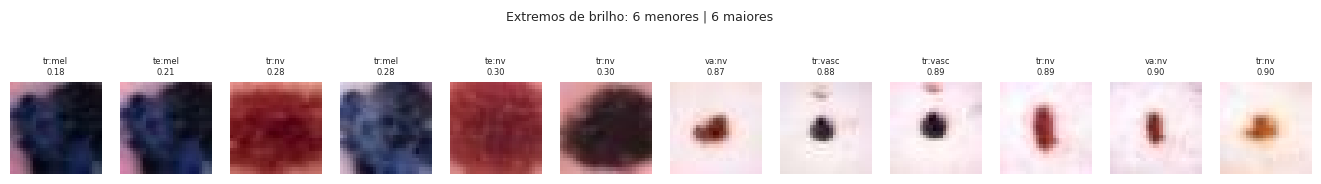

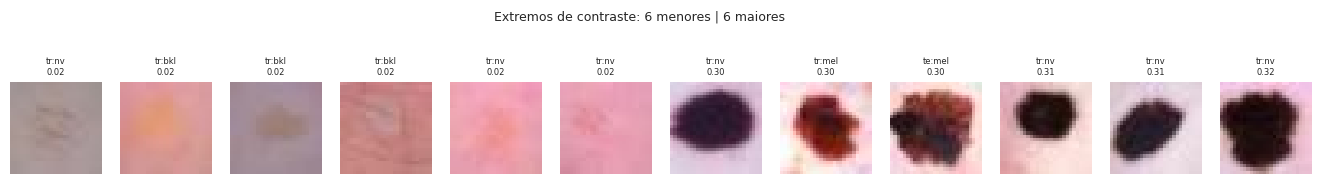

In [10]:
# ---------- 5a. Imagens atípicas (auditoria descritiva em todos os splits)
A = pd.concat([S[s].assign(split=s, idx=np.arange(len(S[s]))) for s in SPLITS], ignore_index=True)
z = lambda s: (s - s.mean()) / s.std()
n_const = int((A['contraste'] < 1e-3).sum())
out = A[(z(A['brilho']).abs() > 4) | (z(A['contraste']).abs() > 4)]
print(f"Imagens constantes (contraste<1e-3): {n_const} | outliers |z|>4 em brilho/contraste: {len(out)}")

def show_extremes(col, k=6):
    srt = A.sort_values(col); sel = pd.concat([srt.head(k), srt.tail(k)])
    fig, axes = plt.subplots(1, 2 * k, figsize=(1.4 * 2 * k, 1.9))
    for a, (_, r) in zip(axes, sel.iterrows()):
        a.imshow(X[r['split']][int(r['idx'])], interpolation='nearest'); a.axis('off')
        a.set_title(f"{r['split'][:2]}:{CODES[y[r['split']][int(r['idx'])]]}\n{r[col]:.2f}", fontsize=6)
    fig.suptitle(f"Extremos de {col}: 6 menores | 6 maiores", fontsize=9, y=1.12); plt.show()
show_extremes('brilho'); show_extremes('contraste')
SUMMARY['atipicas'] = dict(constantes=n_const, outliers_z4=int(len(out)))

In [11]:
# ---------- 5b. Duplicatas exatas (hash dos bytes)
H = pd.concat([pd.DataFrame({'h': [hashlib.md5(a.tobytes()).hexdigest() for a in X[s]], 'split': s, 'idx': np.arange(len(X[s])), 'y': y[s]})
               for s in SPLITS], ignore_index=True)
g = H.groupby('h')
grp = g.agg(n=('h', 'size'), n_splits=('split', 'nunique'), n_rot=('y', 'nunique'))
dup = grp[grp['n'] > 1]
print(f"Grupos de imagens idênticas: {len(dup)} | imagens envolvidas: {int(dup['n'].sum())}")
print(f"  grupos que cruzam splits: {int((dup['n_splits'] > 1).sum())} | grupos com rótulos conflitantes: {int((dup['n_rot'] > 1).sum())}")
SUMMARY['duplicatas_exatas'] = dict(grupos=int(len(dup)), cruzam_splits=int((dup['n_splits'] > 1).sum()),
                                    rotulos_conflitantes=int((dup['n_rot'] > 1).sum()))

Grupos de imagens idênticas: 2 | imagens envolvidas: 4
  grupos que cruzam splits: 0 | grupos com rótulos conflitantes: 0


Quantis da distância ao vizinho mais próximo (menor = mais parecido):


,treino→treino,val→treino,teste→treino
0.001,0.0153,0.0173,0.0136
0.010,0.0303,0.0282,0.0300
0.050,0.0378,0.0379,0.0374
0.250,0.0485,0.0484,0.0483
0.500,0.0583,0.0566,0.0583


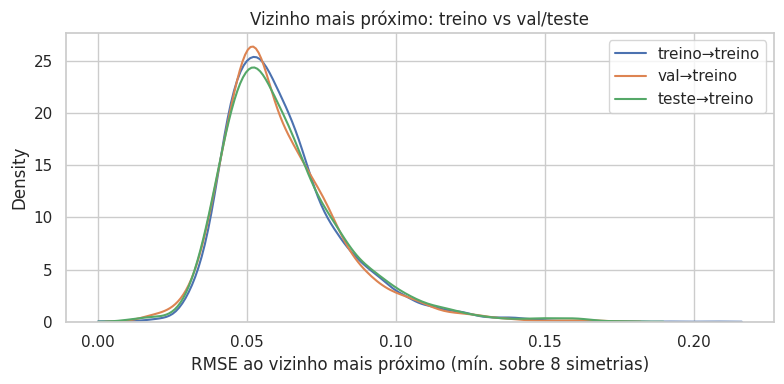

{
  "limiar": 0.03783382847905159,
  "frac_treino_treino(por constru\u00e7\u00e3o)": 0.05,
  "val": {
    "frac_proximos": 0.049850448654037885,
    "razao_vs_treino": 0.9970089730807576,
    "rotulo_igual_nos_proximos": 0.86
  },
  "teste": {
    "frac_proximos": 0.05486284289276808,
    "razao_vs_treino": 1.0972568578553614,
    "rotulo_igual_nos_proximos": 0.8363636363636363
  }
}
razao_vs_treino ≈ 1 => split provavelmente aleatório por imagem (risco de vazamento); ≪ 1 => provavelmente agrupado.


In [12]:
# ---------- 5c. Quase-duplicatas: vizinho mais próximo (RMSE) com as 8 simetrias do grupo diedral, em 28x28 nativo
T28 = {s: resize_np(X[s], 28) for s in SPLITS}

def dihedral(t):
    """(N,3,H,W) -> lista com as 8 variantes (4 rotações x {sem espelho, espelhado})."""
    out = []
    for flip in (False, True):
        u = t.flip(-1) if flip else t
        out += [torch.rot90(u, k, (-2, -1)) for k in range(4)]
    return out

@torch.no_grad()
def nn_dist(Q, R, exclude_self=False, bs=256):
    """Para cada imagem de Q: menor RMSE até R (mínimo sobre as 8 simetrias de Q) e o índice do vizinho em R."""
    Rf = R.flatten(1).to(DEVICE); D = Rf.shape[1]
    best = torch.full((len(Q),), float('inf'), device=DEVICE)
    arg = torch.zeros(len(Q), dtype=torch.long, device=DEVICE)
    for s in range(0, len(Q), bs):
        qs = Q[s:s + bs].to(DEVICE)
        for v in dihedral(qs):
            d = torch.cdist(v.flatten(1), Rf) / D ** 0.5
            if exclude_self:
                r = torch.arange(len(qs), device=DEVICE); d[r, r + s] = float('inf')
            m, a = d.min(1)
            cur = best[s:s + len(qs)]; upd = m < cur
            best[s:s + len(qs)] = torch.where(upd, m, cur)
            arg[s:s + len(qs)] = torch.where(upd, a, arg[s:s + len(qs)])
    return best.cpu(), arg.cpu()

d_tt, a_tt = nn_dist(T28['train'], T28['train'], exclude_self=True)
d_vt, a_vt = nn_dist(T28['val'],   T28['train'])
d_et, a_et = nn_dist(T28['test'],  T28['train'])

qs_ = [0.001, 0.01, 0.05, 0.25, 0.5]
print("Quantis da distância ao vizinho mais próximo (menor = mais parecido):")
display(pd.DataFrame({'treino→treino': np.quantile(d_tt.numpy(), qs_), 'val→treino': np.quantile(d_vt.numpy(), qs_),
                      'teste→treino': np.quantile(d_et.numpy(), qs_)}, index=qs_).round(4))

fig, ax = plt.subplots(figsize=(8, 4))
for d, l in [(d_tt, 'treino→treino'), (d_vt, 'val→treino'), (d_et, 'teste→treino')]:
    sns.kdeplot(d.numpy(), ax=ax, label=l, clip=(0, None))
ax.set_xlabel("RMSE ao vizinho mais próximo (mín. sobre 8 simetrias)"); ax.legend(); ax.set_title("Vizinho mais próximo: treino vs val/teste")
plt.tight_layout(); savefig("eda_vazamento_nn.png"); plt.show()

def leak_report(d_tt, d_vt, d_et, a_vt, a_et, smaller_is_closer=True, q=0.05):
    d_tt, d_vt, d_et = [np.asarray(d) for d in (d_tt, d_vt, d_et)]
    thr = np.quantile(d_tt, q if smaller_is_closer else 1 - q)
    close = (lambda d: d <= thr) if smaller_is_closer else (lambda d: d >= thr)
    res = {'limiar': float(thr), 'frac_treino_treino(por construção)': q}
    for nome, d, a, yq in [('val', d_vt, a_vt, y['val']), ('teste', d_et, a_et, y['test'])]:
        c = close(d); same = (y['train'][np.asarray(a)] == yq)
        res[nome] = dict(frac_proximos=float(c.mean()), razao_vs_treino=float(c.mean() / q),
                         rotulo_igual_nos_proximos=float(same[c].mean()) if c.any() else None)
    print(json.dumps(res, indent=2))
    print("razao_vs_treino ≈ 1 => split provavelmente aleatório por imagem (risco de vazamento); ≪ 1 => provavelmente agrupado.")
    return res
SUMMARY['vazamento_pixels'] = leak_report(d_tt, d_vt, d_et, a_vt, a_et)

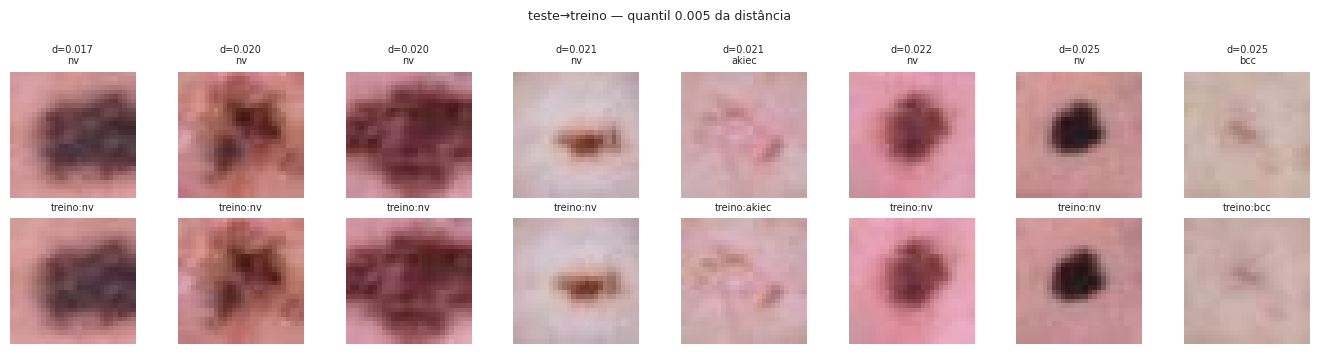

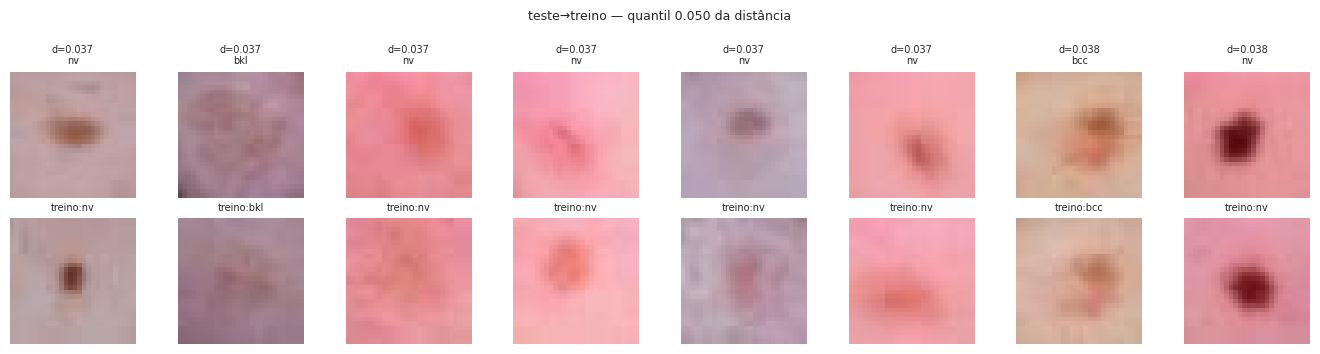

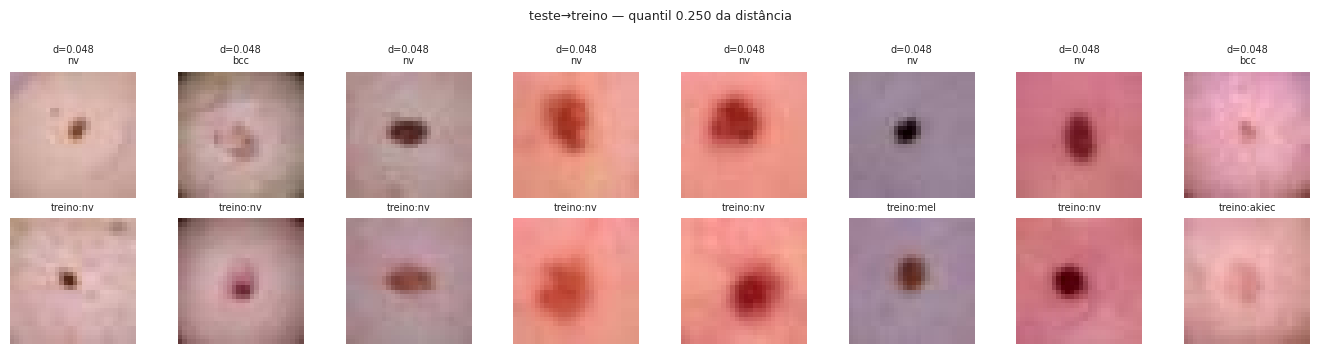

In [13]:
# Inspeção visual (indispensável: calibra o que "muito próximo" significa). Linha de cima: val/teste; baixo: vizinho no treino.
def show_pairs(d, a, Xq, yq, quantile, n=8, title=""):
    d = np.asarray(d); order_ = np.argsort(d); pos = int(quantile * len(d))
    sel = order_[max(0, pos - n // 2): max(0, pos - n // 2) + n]
    fig, axes = plt.subplots(2, len(sel), figsize=(1.7 * len(sel), 3.6))
    for j, i in enumerate(sel):
        axes[0, j].imshow(Xq[i], interpolation='nearest'); axes[0, j].set_title(f"d={d[i]:.3f}\n{CODES[yq[i]]}", fontsize=7)
        nb = int(a[i]); axes[1, j].imshow(X['train'][nb], interpolation='nearest'); axes[1, j].set_title(f"treino:{CODES[y['train'][nb]]}", fontsize=7)
        axes[0, j].axis('off'); axes[1, j].axis('off')
    fig.suptitle(f"{title} — quantil {quantile:.3f} da distância", fontsize=9); plt.tight_layout(); plt.show()

for qv in (0.005, 0.05, 0.25):
    show_pairs(d_et, a_et, X['test'], y['test'], qv, title="teste→treino")

In [14]:
# ---------- 5d. (Opcional, recomendado) mesma pergunta no espaço de FEATURES (ResNet18 ImageNet), mais robusto a pequenas variações
_net = None
def resnet_feats(x_uint8, size=64, bs=256):
    global _net
    import torchvision
    w = torchvision.models.ResNet18_Weights.DEFAULT
    if _net is None:
        _net = torchvision.models.resnet18(weights=w); _net.fc = nn.Identity(); _net = _net.eval().to(DEVICE)
    m = torch.tensor(w.transforms().mean).view(1, 3, 1, 1).to(DEVICE); sd = torch.tensor(w.transforms().std).view(1, 3, 1, 1).to(DEVICE)
    out = []
    with torch.no_grad():
        for i in range(0, len(x_uint8), bs):
            t = resize_np(x_uint8[i:i + bs], size, 'bicubic').to(DEVICE)
            out.append(_net((t - m) / sd).cpu())
    return torch.cat(out)

try:
    FE = {s: F.normalize(resnet_feats(X[s]), dim=1) for s in SPLITS}      # features L2-normalizadas -> produto = cosseno
    sim_tt = FE['train'] @ FE['train'].T; sim_tt.fill_diagonal_(-1.0)
    s_tt, b_tt = sim_tt.max(1); del sim_tt
    s_vt, b_vt = (FE['val'] @ FE['train'].T).max(1)
    s_et, b_et = (FE['test'] @ FE['train'].T).max(1)
    print("Similaridade-cosseno ao vizinho mais próximo (maior = mais parecido)")
    SUMMARY['vazamento_features'] = leak_report(s_tt, s_vt, s_et, b_vt, b_et, smaller_is_closer=False)
except Exception as e:
    print("Etapa 5d ignorada (sem pesos/rede?):", repr(e))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/luma/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 64.8MB/s]


Similaridade-cosseno ao vizinho mais próximo (maior = mais parecido)
{
  "limiar": 0.9481668472290039,
  "frac_treino_treino(por constru\u00e7\u00e3o)": 0.05,
  "val": {
    "frac_proximos": 0.05583250249252243,
    "razao_vs_treino": 1.1166500498504486,
    "rotulo_igual_nos_proximos": 0.875
  },
  "teste": {
    "frac_proximos": 0.04339152119700748,
    "razao_vs_treino": 0.8678304239401496,
    "rotulo_igual_nos_proximos": 0.8850574712643678
  }
}
razao_vs_treino ≈ 1 => split provavelmente aleatório por imagem (risco de vazamento); ≪ 1 => provavelmente agrupado.


## Etapa 6 — Separabilidade das classes (PCA / t-SNE / UMAP)

**Objetivo.** Ver quais classes se sobrepõem e estimar a dificuldade do problema independentemente dos ViTs.

**O que procurar.**
- Sobreposição entre melanoma, nevo e ceratose benigna (esperada). Classes raras isoladas ou misturadas.
- **Não interprete t-SNE/UMAP quantitativamente:** tamanhos de cluster e distâncias entre clusters não são fiéis. Use-os para levantar hipóteses e **confirme com números** (matriz de confusão de um classificador simples, distância entre centróides).
- Em **pixels crus** o resultado reflete cor/brilho globais; com **features** reflete semântica. O ideal é repetir depois com as features (token CLS) do seu próprio ViT/CL-ViT treinado: é uma figura valiosa para o relatório.

**Impacto.** Contexto para a análise de erros: a confusão **melanoma ↔ nevo** é a central, e é o que você vai tentar reduzir ao priorizar o recall do melanoma.

*Honestidade metodológica:* o PCA é ajustado só no treino; t-SNE/UMAP são só para visualização (usam treino).

Variância explicada (50 PCs): 0.971


/home/luma/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/luma/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


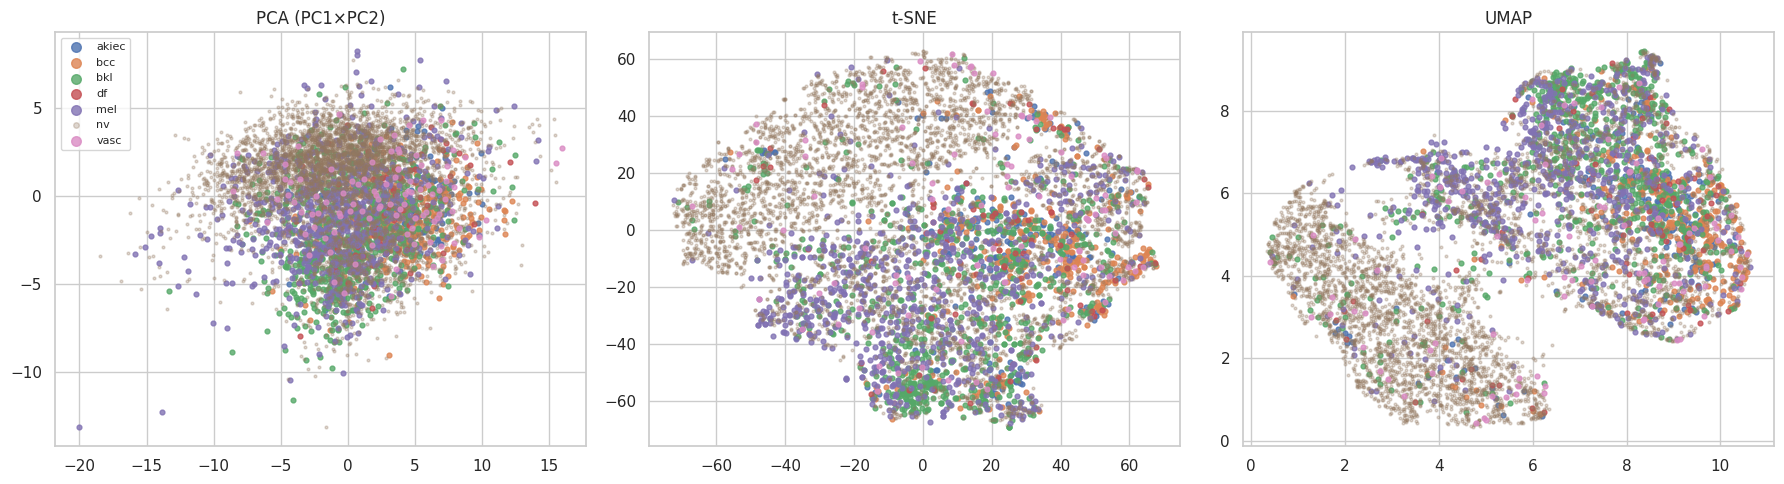

In [15]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

Xf_tr = T32['train'].flatten(1).numpy(); Xf_va = T32['val'].flatten(1).numpy()
pca = PCA(50, random_state=SEED).fit(Xf_tr)                      # ajustado só no treino
Z, Zv = pca.transform(Xf_tr), pca.transform(Xf_va)
print("Variância explicada (50 PCs):", pca.explained_variance_ratio_.sum().round(3))

emb = {'PCA (PC1×PC2)': Z[:, :2],
       't-SNE': TSNE(2, perplexity=30, init='pca', random_state=SEED).fit_transform(Z)}
try:
    import umap
    emb['UMAP'] = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED).fit_transform(Z)
except Exception as e:
    print("UMAP indisponível, seguindo sem ele:", repr(e))

fig, axes = plt.subplots(1, len(emb), figsize=(6 * len(emb), 5))
axes = np.atleast_1d(axes)
for ax, (k, E) in zip(axes, emb.items()):
    for c in range(K):
        m = y['train'] == c
        ax.scatter(E[m, 0], E[m, 1], s=4 if c == NEV else 12, alpha=.3 if c == NEV else .8, label=CODES[c])
    ax.set_title(k)
axes[0].legend(markerscale=2, fontsize=8); plt.tight_layout(); savefig("eda_embeddings_pixels.png"); plt.show()

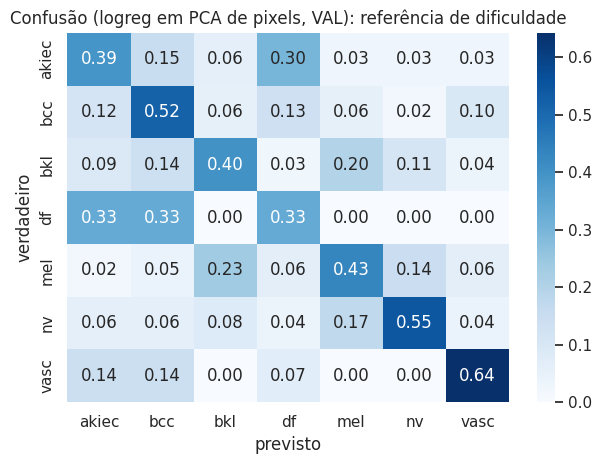

{
  "auc_macro_val": 0.8460662554509716,
  "f1_macro_val": 0.3353013999844842,
  "recall_mel": 0.43243243243243246,
  "mel_previsto_como_nevo": 0.14414414414414414,
  "nevo_previsto_como_mel": 0.17287630402384502
}


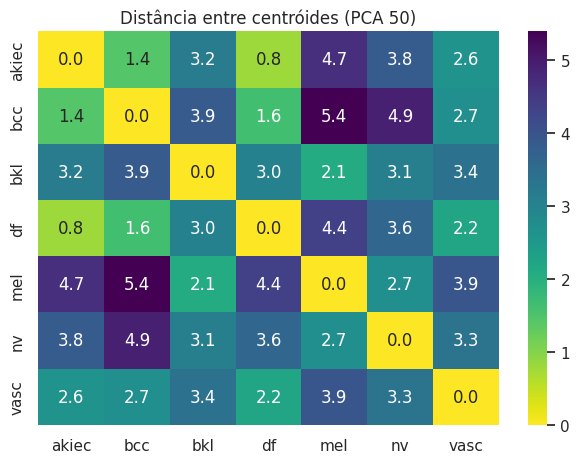

In [16]:
# Quantificando: classificador linear em PCA de pixels (treino -> VAL), confusão normalizada por linha (= recall na diagonal)
clf = LogisticRegression(max_iter=2000, class_weight='balanced').fit(Z, y['train'])
pv = clf.predict_proba(Zv); pr = pv.argmax(1)
cm = confusion_matrix(y['val'], pr, labels=range(K), normalize='true')
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=order, yticklabels=order)
plt.xlabel("previsto"); plt.ylabel("verdadeiro"); plt.title("Confusão (logreg em PCA de pixels, VAL): referência de dificuldade")
plt.tight_layout(); savefig("eda_confusao_baseline_linear.png"); plt.show()

sep = dict(auc_macro_val=float(roc_auc_score(y['val'], pv, multi_class='ovr', average='macro')),
           f1_macro_val=float(f1_score(y['val'], pr, average='macro')),
           recall_mel=float(cm[MEL, MEL]), mel_previsto_como_nevo=float(cm[MEL, NEV]), nevo_previsto_como_mel=float(cm[NEV, MEL]))
print(json.dumps(sep, indent=2)); SUMMARY['baseline_linear_pixels'] = sep

# Distância entre centróides de classe no espaço PCA (menor = mais confundíveis)
cent = np.stack([Z[y['train'] == c].mean(0) for c in range(K)])
Dc = np.linalg.norm(cent[:, None] - cent[None], axis=-1)
sns.heatmap(Dc, annot=True, fmt='.1f', xticklabels=order, yticklabels=order, cmap='viridis_r'); plt.title("Distância entre centróides (PCA 50)")
plt.tight_layout(); savefig("eda_centroides.png"); plt.show()

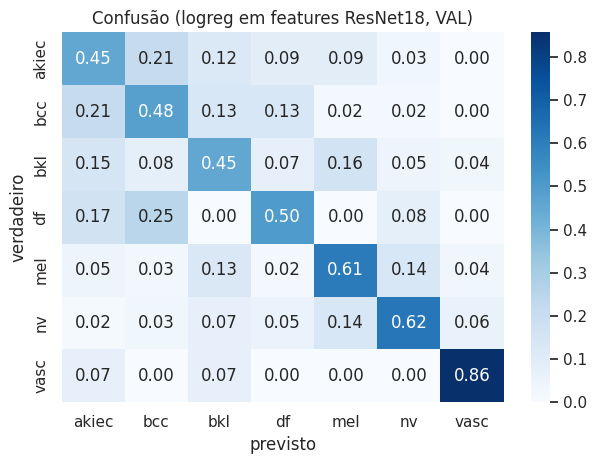

{'auc_macro_val': 0.88802320533542, 'f1_macro_val': 0.4076804196091805, 'recall_mel': 0.6126126126126126}


In [17]:
# (Opcional) Mesma análise com features pré-treinadas (ResNet18 / ImageNet): separabilidade "semântica"
try:
    Ftr, Fva = resnet_feats(X['train']).numpy(), resnet_feats(X['val']).numpy()
    pz = PCA(50, random_state=SEED).fit(Ftr); Zf, Zfv = pz.transform(Ftr), pz.transform(Fva)
    clf_f = LogisticRegression(max_iter=3000, class_weight='balanced').fit(Zf, y['train'])
    pvf = clf_f.predict_proba(Zfv); prf = pvf.argmax(1)
    cmf = confusion_matrix(y['val'], prf, labels=range(K), normalize='true')
    sns.heatmap(cmf, annot=True, fmt='.2f', cmap='Blues', xticklabels=order, yticklabels=order)
    plt.title("Confusão (logreg em features ResNet18, VAL)"); plt.xlabel("previsto"); plt.ylabel("verdadeiro")
    plt.tight_layout(); savefig("eda_confusao_baseline_features.png"); plt.show()
    SUMMARY['baseline_linear_features'] = dict(auc_macro_val=float(roc_auc_score(y['val'], pvf, multi_class='ovr', average='macro')),
                                               f1_macro_val=float(f1_score(y['val'], prf, average='macro')), recall_mel=float(cmf[MEL, MEL]))
    print(SUMMARY['baseline_linear_features'])
except Exception as e:
    print("Variante com features ignorada:", repr(e))

## Etapa 7 — Impacto da resolução (opcional)

**Objetivo.** Entender o que se perde em 28×28/32×32. Em dermatoscopia o diagnóstico depende de textura fina (rede de pigmento, pontos/glóbulos, estruturas vasculares) e de bordas da lesão. Em 28 px grande parte disso é destruída; sobram basicamente **forma, cor e distribuição de cor**.

**Como medir.** Compara-se a mesma imagem em outras resoluções (`size=64`, exige `medmnist >= 3`) e mede-se o efeito no desempenho de um **classificador simples** (PCA + regressão logística), treino → **validação**.

**Cuidado na interpretação.** Um classificador linear em pixels **não captura textura fina**; diferença pequena aqui **não prova** que a resolução não importa. Para um argumento forte, repita com uma CNN pequena. Se 32→64 melhorar muito, registre como **limitação** do 28/32 e motivação de trabalho futuro. Usar 64 reduzido para 32 foge do "28 nativo" do protocolo e perde a comparabilidade direta com os baselines de 28×28: só como ablação.

100%|██████████| 100M/100M [03:24<00:00, 490kB/s]  


Correlação média 64→28 vs 28 nativo: 0.992


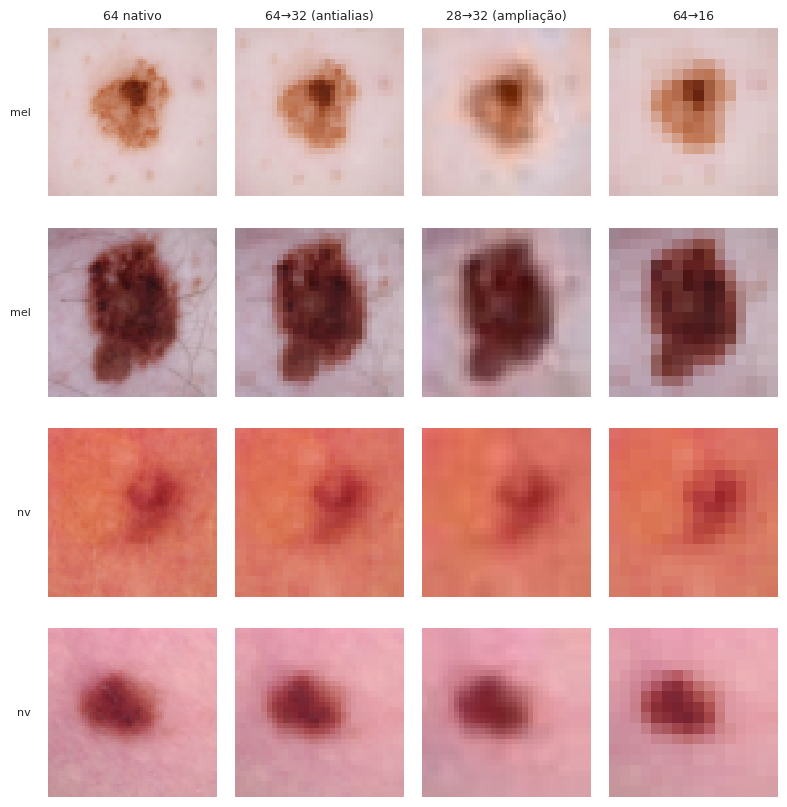

,f1_macro,auc_macro
16 (de 64),0.354,0.853
28 (nativo),0.327,0.842
32 (de 28),0.323,0.840
32 (de 64),0.339,0.845
64 (nativo),0.343,0.843


In [18]:
HAS64 = True
try:
    ds64 = {s: DermaMNIST(split=s, download=True, root=DATA_DIR, size=64) for s in ('train', 'val')}
    X64 = {s: np.asarray(ds64[s].imgs) for s in ds64}
    for s in ds64: assert (np.asarray(ds64[s].labels).ravel() == y[s]).all(), f"ordem/rótulos diferem entre tamanhos em {s}!"
except Exception as e:
    HAS64 = False; print("Etapa 7 ignorada (precisa de medmnist>=3 e rede):", repr(e))

if HAS64:
    # Mesmo conteúdo? (correlação entre 64->28 com antialias e o 28 nativo)
    a = resize_np(X64['train'][:200], 28, 'bilinear', antialias=True).flatten(1).numpy()
    b = resize_np(X['train'][:200], 28).flatten(1).numpy()
    print("Correlação média 64→28 vs 28 nativo:", np.mean([np.corrcoef(a[i], b[i])[0, 1] for i in range(200)]).round(3))

    ex = [np.where(y['train'] == c)[0][j] for c in (MEL, NEV) for j in (0, 1)]
    titles = ["64 nativo", "64→32 (antialias)", "28→32 (ampliação)", "64→16"]
    fig, axes = plt.subplots(len(ex), 4, figsize=(8, 2.1 * len(ex)))
    for r, i in enumerate(ex):
        v = [X64['train'][i], to_uint8_img(resize_np(X64['train'][i:i+1], 32, 'bicubic', True)),
             to_uint8_img(resize_np(X['train'][i:i+1], 32, 'bicubic')), to_uint8_img(resize_np(X64['train'][i:i+1], 16, 'bicubic', True))]
        for c, im in enumerate(v):
            axes[r, c].imshow(im, interpolation='nearest'); axes[r, c].axis('off')
            if r == 0: axes[r, c].set_title(titles[c], fontsize=9)
        axes[r, 0].text(-0.1, .5, CODES[y['train'][i]], transform=axes[r, 0].transAxes, ha='right', va='center', fontsize=8)
    plt.tight_layout(); savefig("eda_resolucao.png"); plt.show()

    def probe(xtr, xva, res, antialias):
        ftr = resize_np(xtr, res, 'bicubic', antialias).flatten(1).numpy(); fva = resize_np(xva, res, 'bicubic', antialias).flatten(1).numpy()
        p = PCA(100, svd_solver='randomized', random_state=SEED).fit(ftr)
        m = LogisticRegression(max_iter=1500, class_weight='balanced').fit(p.transform(ftr), y['train'])
        pr_ = m.predict_proba(p.transform(fva))
        return dict(f1_macro=f1_score(y['val'], pr_.argmax(1), average='macro'),
                    auc_macro=roc_auc_score(y['val'], pr_, multi_class='ovr', average='macro'))
    res_tab = {'16 (de 64)': probe(X64['train'], X64['val'], 16, True), '28 (nativo)': probe(X['train'], X['val'], 28, False),
               '32 (de 28)': probe(X['train'], X['val'], 32, False), '32 (de 64)': probe(X64['train'], X64['val'], 32, True),
               '64 (nativo)': probe(X64['train'], X64['val'], 64, False)}
    res_df = pd.DataFrame(res_tab).T.round(3); display(res_df)
    SUMMARY['resolucao_probe_linear'] = res_df.to_dict()

## Etapa 8 — Implicações para os ViTs: patch, tokens, SPT, CutMix e parâmetros por amostra

**Objetivo.** Traduzir o EDA em decisões de arquitetura/treino.

**Fatos.**
- Entrada 32×32; com patch `P` há `(32/P)²` tokens. **"Patch 4×4" = 4×4 pixels = grade 8×8 = 64 tokens** (não uma grade 4×4).
- O **SPT** concatena 5 versões da imagem (original + 4 deslocamentos diagonais de `P/2`), então a dimensão do patch passa de `3P²` para `15P²`.
- O stem do **CL-ViT** com duas convs 3×3 stride 2 tem stride total 4 (≡ `P=4`); com `P=8` seriam três convs. O número de tokens fica igual ao do ViT/SL-ViT (comparação justa).
- **Confirme nos arquivos de configuração do repositório** (patch, profundidade, dimensão, política de AutoAugment, parâmetros de CutMix/Mixup) em vez de assumir.

**Raciocínio.**
- `P=2` (256 tokens): granularidade fina, mas custo quadrático em atenção e cada token carrega pouquíssima informação. `P=8` (16 tokens): grosseiro demais para lesões pequenas. `P=4` (64 tokens) é o compromisso natural e o do artigo para 32×32. Patch como fator experimental só se sobrar tempo.
- **Overfitting:** com ~7 mil imagens e um ViT de milhões de parâmetros há centenas de parâmetros por imagem. Monitore a **diferença treino–validação** por época.
- **CutMix e lesão centralizada:** se a imagem média (Etapa 4) mostra a lesão no centro, um recorte aleatório pode apagar a lesão mantendo (parte do) rótulo, o que é **ruído de rótulo** e prejudica as classes raras. A simulação abaixo estima com que frequência o retângulo cobre o centro. Multiplique pela probabilidade de aplicação do CutMix no seu repositório.

,patch,grade,tokens,pixels_por_patch,dim_patch_SPT,pares_de_atencao,convs_stride2_no_stem_CL
0,2,16x16,256,12,60,65536,1
1,4,8x8,64,48,240,4096,2
2,8,4x4,16,192,960,256,3


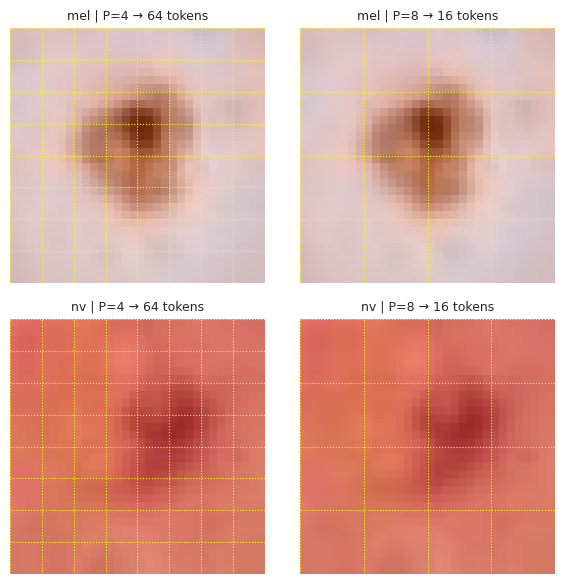

In [19]:
# --- Tabela patch × tokens × dimensão do patch (ViT vs SPT) × atenção
rows = []
for P in (2, 4, 8):
    n = (32 // P) ** 2
    rows.append(dict(patch=P, grade=f"{32 // P}x{32 // P}", tokens=n, pixels_por_patch=3 * P * P, dim_patch_SPT=15 * P * P,
                     pares_de_atencao=n * n, convs_stride2_no_stem_CL=int(np.log2(P))))
patch_tab = pd.DataFrame(rows); display(patch_tab); SUMMARY['tabela_patch'] = patch_tab.to_dict('records')

# --- Grade de patches sobre melanoma e nevo (P=4 e P=8)
fig, axes = plt.subplots(2, 2, figsize=(6, 6))
for r, c in enumerate((MEL, NEV)):
    i = np.where(y['train'] == c)[0][0]; img = T32['train'][i].permute(1, 2, 0).numpy()
    for k, P in enumerate((4, 8)):
        axes[r, k].imshow(img); axes[r, k].axis('off')
        for v in range(0, 32, P):
            axes[r, k].axvline(v - .5, color='yellow', ls=':', lw=.8); axes[r, k].axhline(v - .5, color='yellow', ls=':', lw=.8)
        axes[r, k].set_title(f"{CODES[c]} | P={P} → {(32 // P) ** 2} tokens", fontsize=9)
plt.tight_layout(); savefig("eda_patch_grid_derma.png"); plt.show()

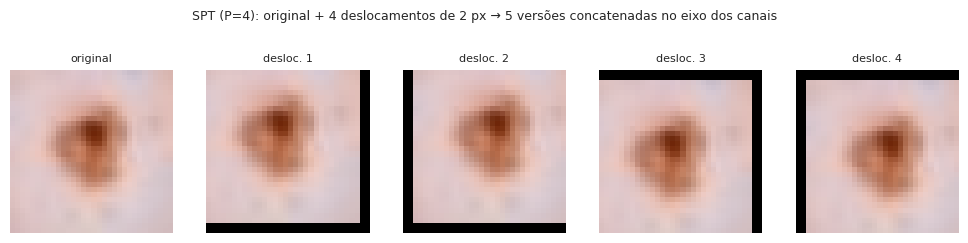

Em 32 px, um deslocamento de 2 px já move a lesão em ~6% da largura; as bordas ficam com zeros (padding).


In [20]:
# --- Visualização do SPT: imagem original + 4 deslocamentos diagonais de P/2 (preenchimento com zeros)
def spt_shifts(x, P):
    s = P // 2; H = x.shape[-1]; xp = F.pad(x, (s, s, s, s))
    return [xp[..., s + dy: s + dy + H, s + dx: s + dx + H] for dy, dx in [(s, s), (s, -s), (-s, s), (-s, -s)]]

i = np.where(y['train'] == MEL)[0][0]; x1 = T32['train'][i:i + 1]
fig, axes = plt.subplots(1, 5, figsize=(10, 2.3))
for a, (im, t) in zip(axes, zip([x1] + spt_shifts(x1, 4), ["original", "desloc. 1", "desloc. 2", "desloc. 3", "desloc. 4"])):
    a.imshow(im[0].permute(1, 2, 0).numpy(), interpolation='nearest'); a.set_title(t, fontsize=8); a.axis('off')
fig.suptitle("SPT (P=4): original + 4 deslocamentos de 2 px → 5 versões concatenadas no eixo dos canais", fontsize=9, y=1.05)
plt.tight_layout(); savefig("eda_spt_shifts.png"); plt.show()
print("Em 32 px, um deslocamento de 2 px já move a lesão em ~6% da largura; as bordas ficam com zeros (padding).")

In [21]:
# --- CutMix: com que frequência o retângulo cobre o centro (onde a lesão costuma estar)?
def cutmix_box_stats(n=200_000, W=32, alpha=1.0, center=8, seed=SEED):
    rng = np.random.default_rng(seed)
    lam = rng.beta(alpha, alpha, n); cw = (W * np.sqrt(1 - lam)).astype(int)
    cx, cy = rng.integers(0, W, n), rng.integers(0, W, n)
    x1, x2 = np.clip(cx - cw // 2, 0, W), np.clip(cx + cw // 2, 0, W)
    y1, y2 = np.clip(cy - cw // 2, 0, W), np.clip(cy + cw // 2, 0, W)
    lo, hi = (W - center) // 2, (W + center) // 2
    return dict(alpha=alpha, area_media_substituida=float((((x2 - x1) * (y2 - y1)) / W ** 2).mean()),
                p_cobre_todo_o_centro=float(((x1 <= lo) & (x2 >= hi) & (y1 <= lo) & (y2 >= hi)).mean()),
                p_toca_o_centro=float(((x1 < hi) & (x2 > lo) & (y1 < hi) & (y2 > lo)).mean()))
cm_stats = pd.DataFrame([cutmix_box_stats(alpha=a) for a in (1.0, 0.5)]).round(3)
display(cm_stats)
print("Região central = 8×8 px. Confira no repositório o alpha do CutMix e a probabilidade de aplicação.")
SUMMARY['cutmix_mc'] = cm_stats.to_dict('records')

,alpha,area_media_substituida,p_cobre_todo_o_centro,p_toca_o_centro
0,1.0,0.299,0.228,0.715
1,0.5,0.291,0.238,0.669


Região central = 8×8 px. Confira no repositório o alpha do CutMix e a probabilidade de aplicação.


In [22]:
# --- Parâmetros por amostra de treino (estimativa ANALÍTICA; confirme a configuração real no repositório)
def vit_params(dim=192, depth=9, mlp_ratio=2, patch_dim=48, n_tokens=64, n_classes=7, spt=False):
    d, h = dim, int(dim * mlp_ratio)
    patch_embed = patch_dim * d + d + (2 * patch_dim if spt else 0)       # (SPT) + LayerNorm sobre 15·P²
    pos_cls = (n_tokens + 1) * d + d
    block = (3 * d * d + 3 * d) + (d * d + d) + (d * h + h) + (h * d + d) + 4 * d     # qkv + proj + MLP + 2 LN
    head = 2 * d + d * n_classes + n_classes
    return patch_embed + pos_cls + depth * block + head

n_train = len(y['train'])
rows = []
for P in (4, 8):
    nt = (32 // P) ** 2
    for nome, spt in (('ViT', False), ('SL-ViT/S-ViT (SPT)', True)):
        pm = vit_params(patch_dim=(15 if spt else 3) * P * P, n_tokens=nt, spt=spt)
        rows.append(dict(modelo=nome, patch=P, tokens=nt, params_M=round(pm / 1e6, 3), params_por_imagem_treino=round(pm / n_train)))
display(pd.DataFrame(rows))
print("HIPÓTESE (confirmar no repo): dim=192, depth=9, mlp_ratio=2. O stem do CL-ViT e a temperatura do LSA somam pouco/modelo-dependente.")
print("Para o valor exato:  sum(p.numel() for p in model.parameters() if p.requires_grad)")

,modelo,patch,tokens,params_M,params_por_imagem_treino
0,ViT,4,64,2.697,385
1,SL-ViT/S-ViT (SPT),4,64,2.734,390
2,ViT,8,16,2.715,388
3,SL-ViT/S-ViT (SPT),8,16,2.865,409


HIPÓTESE (confirmar no repo): dim=192, depth=9, mlp_ratio=2. O stem do CL-ViT e a temperatura do LSA somam pouco/modelo-dependente.
Para o valor exato:  sum(p.numel() for p in model.parameters() if p.requires_grad)


## Etapa 9 — Ponte para o balanceamento e para as extensões (tudo calculado só com o treino)

**Objetivo.** Deixar prontos, **a partir de `y['train']`**, os insumos das estratégias de balanceamento e dimensionar os experimentos opcionais.

**O que olhar.**
- **Distribuição efetiva do `WeightedRandomSampler`** para `α ∈ {0, 0,5, 1}`: a classe `c` passa a ter massa ∝ `n_c^(1−α)`. `α=0` é a distribuição original, `α=1` é balanceamento total, `α=0,5` é o meio-termo (raiz quadrada). Veja quantas imagens de melanoma e de df entram, em média, em um batch.
- **Pesos de classe** (inverso, raiz do inverso, *effective number*) normalizados para `E_prior[w] = 1`, de modo que a escala do gradiente/LR não mude.
- **Subconjuntos estratificados (10/25/50/100%)** e **folds da validação cruzada:** quantas imagens das classes raras sobram. Com 10% do treino as classes raras ficam com poucas imagens (≈ 8 para o df), então o balanceamento passa a pesar muito mais e as métricas ficam muito ruidosas.

**Regras anti-vazamento.** Nada daqui toca validação/teste. Nos subconjuntos e nos folds, **pesos, sampler e priors são recalculados a partir do treino de cada subconjunto/fold**.

In [23]:
from torch.utils.data import WeightedRandomSampler
from sklearn.model_selection import StratifiedKFold, train_test_split

cnt_tr = np.bincount(y['train'], minlength=K).astype(float); prior = cnt_tr / cnt_tr.sum()

# --- Distribuição efetiva do sampler (analítica e simulada) para alfa = 0, 0.5, 1
def effective_dist(cnt_, alpha): p = cnt_ ** (1 - alpha); return p / p.sum()
def simulate_sampler(y_train, alpha, seed=SEED):
    c = np.bincount(y_train, minlength=K).astype(float); w = (c ** -alpha)[y_train]
    smp = WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double), num_samples=len(y_train), replacement=True,
                                generator=torch.Generator().manual_seed(seed))
    drawn = np.array(list(smp)); return np.bincount(y_train[drawn], minlength=K) / len(drawn)

eff = pd.DataFrame({f"alfa={a}": effective_dist(cnt_tr, a) for a in (0, 0.5, 1)}, index=order)
sim = pd.DataFrame({f"alfa={a} (simulado)": simulate_sampler(y['train'], a) for a in (0, 0.5, 1)}, index=order)
display(pd.concat([(eff * 100).round(2), (sim * 100).round(2)], axis=1))
B = 128   # tamanho de batch: ajuste para o seu
print(f"Esperado por batch de {B}:  melanoma =", {f"alfa={a}": round(B * effective_dist(cnt_tr, a)[MEL], 1) for a in (0, .5, 1)},
      "| df =", {f"alfa={a}": round(B * effective_dist(cnt_tr, a)[[k for k, c in CODES.items() if c == 'df'][0]], 1) for a in (0, .5, 1)})

# --- Pesos de classe (normalizados: E_{y~prior}[w_y] = 1)
def class_weights(cnt_, mode='inv_sqrt', beta=0.999):
    w = {'inv': 1 / cnt_, 'inv_sqrt': 1 / np.sqrt(cnt_), 'effective': (1 - beta) / (1 - beta ** cnt_)}[mode]
    return w / (w * (cnt_ / cnt_.sum())).sum()
W = pd.DataFrame({m: class_weights(cnt_tr, m) for m in ('inv', 'inv_sqrt', 'effective')}, index=order).round(3); display(W)
print("Pesos muito extremos (razão max/min grande) tendem a desestabilizar o treino; compare as razões:",
      {m: round(float(W[m].max() / W[m].min()), 1) for m in W})

# Priors/log-priors (para logit adjustment) e minoritárias (<5% do treino)
minority = [CODES[i] for i in range(K) if prior[i] < 0.05]
print("Classes minoritárias (<5% do treino):", minority)
SUMMARY['insumos_balanceamento'] = dict(prior=dict(zip(order, prior.round(5))), log_prior=dict(zip(order, np.log(prior).round(4))),
                                        pesos=W.to_dict(), distribuicao_efetiva_sampler=(eff).round(4).to_dict(), minoritarias=minority)

,alfa=0,alfa=0.5,alfa=1,alfa=0 (simulado),alfa=0.5 (simulado),alfa=1 (simulado)
akiec,3.25,8.53,14.29,3.25,7.88,13.81
bcc,5.12,10.70,14.29,4.54,11.05,13.79
bkl,10.97,15.66,14.29,10.89,16.08,14.04
df,1.14,5.05,14.29,1.18,5.42,14.83
mel,11.12,15.76,14.29,11.07,14.63,15.08
nv,66.98,38.68,14.29,67.73,38.78,14.33
vasc,1.41,5.62,14.29,1.33,6.17,14.11


Esperado por batch de 128:  melanoma = {'alfa=0': np.float64(14.2), 'alfa=0.5': np.float64(20.2), 'alfa=1': np.float64(18.3)} | df = {'alfa=0': np.float64(1.5), 'alfa=0.5': np.float64(6.5), 'alfa=1': np.float64(18.3)}


,inv,inv_sqrt,effective
akiec,4.390,2.620,2.861
bcc,2.788,2.088,1.934
bkl,1.302,1.427,1.087
df,12.513,4.424,7.588
mel,1.285,1.418,1.078
nv,0.213,0.578,0.589
vasc,10.111,3.977,6.189


Pesos muito extremos (razão max/min grande) tendem a desestabilizar o treino; compare as razões: {'inv': 58.7, 'inv_sqrt': 7.7, 'effective': 12.9}
Classes minoritárias (<5% do treino): ['akiec', 'df', 'vasc']


In [24]:
# --- Subconjuntos estratificados do TREINO (val/teste ficam intactos) e folds da validação cruzada
rows = []
for frac in (0.10, 0.25, 0.50):
    idx, _ = train_test_split(np.arange(len(y['train'])), train_size=frac, stratify=y['train'], random_state=SEED)
    rows.append(dict(fracao=f"{int(frac * 100)}%", n=len(idx), **{CODES[c]: int((y['train'][idx] == c).sum()) for c in range(K)}))
rows.append(dict(fracao="100%", n=len(y['train']), **{CODES[c]: int(cnt_tr[c]) for c in range(K)}))
sub = pd.DataFrame(rows); display(sub)

skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
f_tr, f_va = zip(*[(len(a), np.bincount(y['train'][b], minlength=K)) for a, b in skf.split(np.zeros(len(y['train'])), y['train'])])
print(f"5-fold sobre o treino: {f_tr[0]} treino / {len(y['train']) - f_tr[0]} validação por fold. Contagem por classe na validação do fold 1:",
      dict(zip(order, f_va[0])))
print("Nota: no 5-fold, pesos/sampler/priors e offsets devem ser recalculados DENTRO de cada fold. Se houver vazamento por lesão (Etapa 5), a CV também fica otimista.")
SUMMARY['subconjuntos'] = sub.to_dict('records')

,fracao,n,akiec,bcc,bkl,df,mel,nv,vasc
0,10%,700,22,36,77,8,78,469,10
1,25%,1751,57,90,192,20,194,1173,25
2,50%,3503,114,180,384,40,389,2346,50
3,100%,7007,228,359,769,80,779,4693,99


5-fold sobre o treino: 5605 treino / 1402 validação por fold. Contagem por classe na validação do fold 1: {'akiec': np.int64(46), 'bcc': np.int64(72), 'bkl': np.int64(154), 'df': np.int64(16), 'mel': np.int64(155), 'nv': np.int64(939), 'vasc': np.int64(20)}
Nota: no 5-fold, pesos/sampler/priors e offsets devem ser recalculados DENTRO de cada fold. Se houver vazamento por lesão (Etapa 5), a CV também fica otimista.


## Etapa 10 — Resumo e checklist para o relatório IEEE

Salva o resumo numérico (`reports/eda_summary.json`) e imprime as decisões que devem ser **fixadas e registradas** antes dos treinos finais.

In [25]:
with open(os.path.join(OUT_DIR, "eda_summary.json"), "w", encoding="utf-8") as f:
    json.dump(SUMMARY, f, indent=2, default=jsonable, ensure_ascii=False)
print("Salvo: reports/eda_summary.json | reports/normalization.json | figuras em reports/figures/\n")

print("=== DECISÕES A FIXAR E REGISTRAR ===")
print(f"- Melanoma = índice {MEL} ({CODES[MEL]}), nevo = índice {NEV} ({CODES[NEV]})  [lidos do INFO]")
print(f"- Interpolação 28→32: {INTERP} (igual em TODOS os modelos e igual à do repositório de treino)")
print(f"- Normalização (treino, 32×32): mean={NORM['mean']} std={NORM['std']}")
print(f"- IR treino = {IR:.1f}:1 | acurácia trivial (val) = {trivial['val']:.3f}")
print("- Balanceamento: calcule SEMPRE a partir de y['train']; offsets/limiares apenas na validação")
print("- Patch: 4 (64 tokens), salvo ablação | confirmar config do repositório (dim, depth, AutoAugment, CutMix/Mixup)")

Salvo: reports/eda_summary.json | reports/normalization.json | figuras em reports/figures/

=== DECISÕES A FIXAR E REGISTRAR ===
- Melanoma = índice 4 (mel), nevo = índice 5 (nv)  [lidos do INFO]
- Interpolação 28→32: bilinear (igual em TODOS os modelos e igual à do repositório de treino)
- Normalização (treino, 32×32): mean=[0.763099, 0.538066, 0.561366] std=[0.135438, 0.152966, 0.167904]
- IR treino = 58.7:1 | acurácia trivial (val) = 0.669
- Balanceamento: calcule SEMPRE a partir de y['train']; offsets/limiares apenas na validação
- Patch: 4 (64 tokens), salvo ablação | confirmar config do repositório (dim, depth, AutoAugment, CutMix/Mixup)


### Checklist do que documentar no relatório (IEEE)
- [ ] Versões (`medmnist`, `torch`, seed) e confirmação de que os splits são os **oficiais**, com contagens por split.
- [ ] Mapeamento índice → classe **lido do `INFO`** e o índice usado como "melanoma".
- [ ] Tabela de contagem/proporção por classe e split; IR; acurácia do classificador trivial; qui-quadrado; ICs possíveis para o recall das classes raras.
- [ ] Figura de exemplos por classe; comparação 28 vs 32 e **interpolação escolhida** (+ justificativa e igualdade em todos os modelos).
- [ ] Média/desvio **globais** por canal (do treino, após resize) usados na normalização (`normalization.json`).
- [ ] Brilho/contraste por classe, imagem média/desvio por classe; teste de atalho de cor; comentário sobre AutoAugment de cor e CutMix.
- [ ] Resultado das imagens atípicas (ou "nenhuma") e das duplicatas exatas (e conflitos de rótulo).
- [ ] Diagnóstico de vazamento: distribuições treino→treino vs val/teste→treino, razão, exemplos visuais, **declaração da limitação**.
- [ ] PCA/t-SNE/UMAP + matriz de confusão do baseline linear; observações sobre melanoma × nevo.
- [ ] (Opcional) Impacto da resolução e limitações do 28/32.
- [ ] Tabela patch × tokens × dim. do patch × parâmetros por amostra; patch escolhido e justificativa.
- [ ] Insumos de balanceamento (priors, pesos, distribuição efetiva do sampler) e contagens dos subconjuntos/folds.
- [ ] Declaração explícita: **o teste não influenciou nenhuma decisão**; balanceamento só no treino; relatório da **última época**.